# Modelación Computacional para SUT: Herramientas y Procesos

---

## Autor: Santiago Ayala

---

¡Bienvenid@ a mi notebook! 👻👻👻

Este *notebook* registra paso a paso las metodologías, herramientas y flujos de trabajo usados en la **modelación computacional** del proyecto SUT 2026: desde la descarga de la red peatonal de OpenStreetMap hasta una red limpia de **La Aurora (Medellín)** con los **puntos de interés integrados como nodos**, lista para los cálculos topológicos y de accesibilidad.

**Objetivo principal:** dejar un flujo reproducible y documentado que cualquier integrante del semillero pueda volver a ejecutar.

**Nota:** las funciones del flujo están en `src/red_peatonal.py`; aquí se usan y se explica qué hace cada una.

## 📑 Tabla de Contenido

1. [Configuración del entorno de trabajo](#paso-1)
2. [Formas de descargar redes con OSMnx](#paso-2)
3. [Red peatonal de La Aurora: descarga, recorte y limpieza](#paso-3)
4. [Integración de los puntos de interés a la red](#paso-4)
5. [Exportación de resultados](#paso-5)
6. [Primer vistazo topológico](#paso-6)
7. [Próximos pasos](#paso-7)

```
 Red OSM (walk)  ──►  Recorte por polígono  ──►  Exclusiones manuales  ──►  Componente principal
                                                                                   │
   GraphML / GPKG  ◄──  Verificación  ◄──  Integración de POIs  ◄──  Proyección EPSG:9377
```

<a id="paso-1"></a>
## 1. Configuración del entorno de trabajo e importación de librerías

Nos apoyamos en librerías de análisis espacial y teoría de grafos:

| Librería | Para qué se usa |
|---|---|
| `osmnx` | Descarga la infraestructura real (calles, redes peatonales) desde OpenStreetMap y la convierte en grafos. |
| `networkx` | Maneja el grafo (nodos y aristas) para calcular conectividad, distancias y rutas. |
| `geopandas` | Maneja geometrías (puntos, líneas, polígonos) en tablas y permite cruces espaciales. |

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
import pandas as pd
from IPython.display import Image, display

# Funciones propias del proyecto (carpeta src/)
sys.path.insert(0, str(Path("..", "src").resolve()))
import red_peatonal as rp

ox.settings.log_console = False   # True para ver el progreso de las descargas
ox.settings.use_cache = True
ox.settings.cache_folder = "../cache"  # la caché NO se sube a GitHub (.gitignore)

print("OSMnx", ox.__version__, "| NetworkX", nx.__version__, "| GeoPandas", gpd.__version__)

OSMnx 2.1.1 | NetworkX 3.7 | GeoPandas 1.2.0


In [2]:
# Rutas del proyecto
GPKG = Path("../GPKG")
ENTRADAS = GPKG / "Aurora" / "Entradas"
RESULTADOS = GPKG / "Aurora" / "Resultados"
IMAGENES = Path("../Images")
RESULTADOS.mkdir(parents=True, exist_ok=True)

# Estilo de las figuras (mismos colores de siempre)
FONDO, EJES, NODOS = "#0B1F33", "#1479FF", "#20C997"
estilo = dict(bgcolor=FONDO, edge_color=EJES, node_color=NODOS, node_size=2, edge_linewidth=1)

<a id="paso-2"></a>
## 2. Formas de descargar redes con OSMnx

Hay tres alternativas principales para delimitar la zona de estudio. Como descargar todo Medellín o el AMVA tarda varios minutos, estos ejemplos sólo se ejecutan si `EJECUTAR_EJEMPLOS = True`; si no, se muestra la figura que ya se guardó.

In [3]:
EJECUTAR_EJEMPLOS = False

**2.1 Por nombre del lugar (`graph_from_place`):** se ingresa el nombre oficial de la ciudad, comuna o barrio y OSMnx busca su límite político-administrativo.

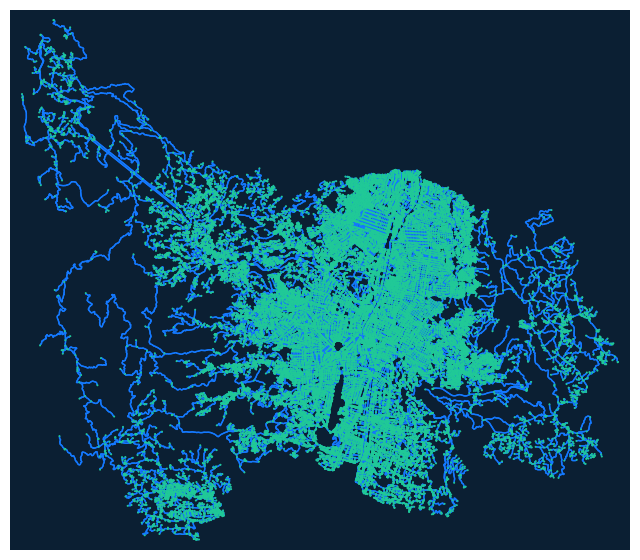

In [4]:
if EJECUTAR_EJEMPLOS:
    A = ox.graph.graph_from_place("Medellín, Antioquia, Colombia", network_type="walk")
    fig, ax = ox.plot.plot_graph(A, **estilo)
else:
    display(Image(filename=IMAGENES / "Medellin_graph_from_place.png", width=500))

**2.2 Por polígono (`graph_from_polygon`):** ideal cuando el área de estudio tiene una forma específica dibujada en QGIS. Aquí se usa el polígono del municipio de Medellín.

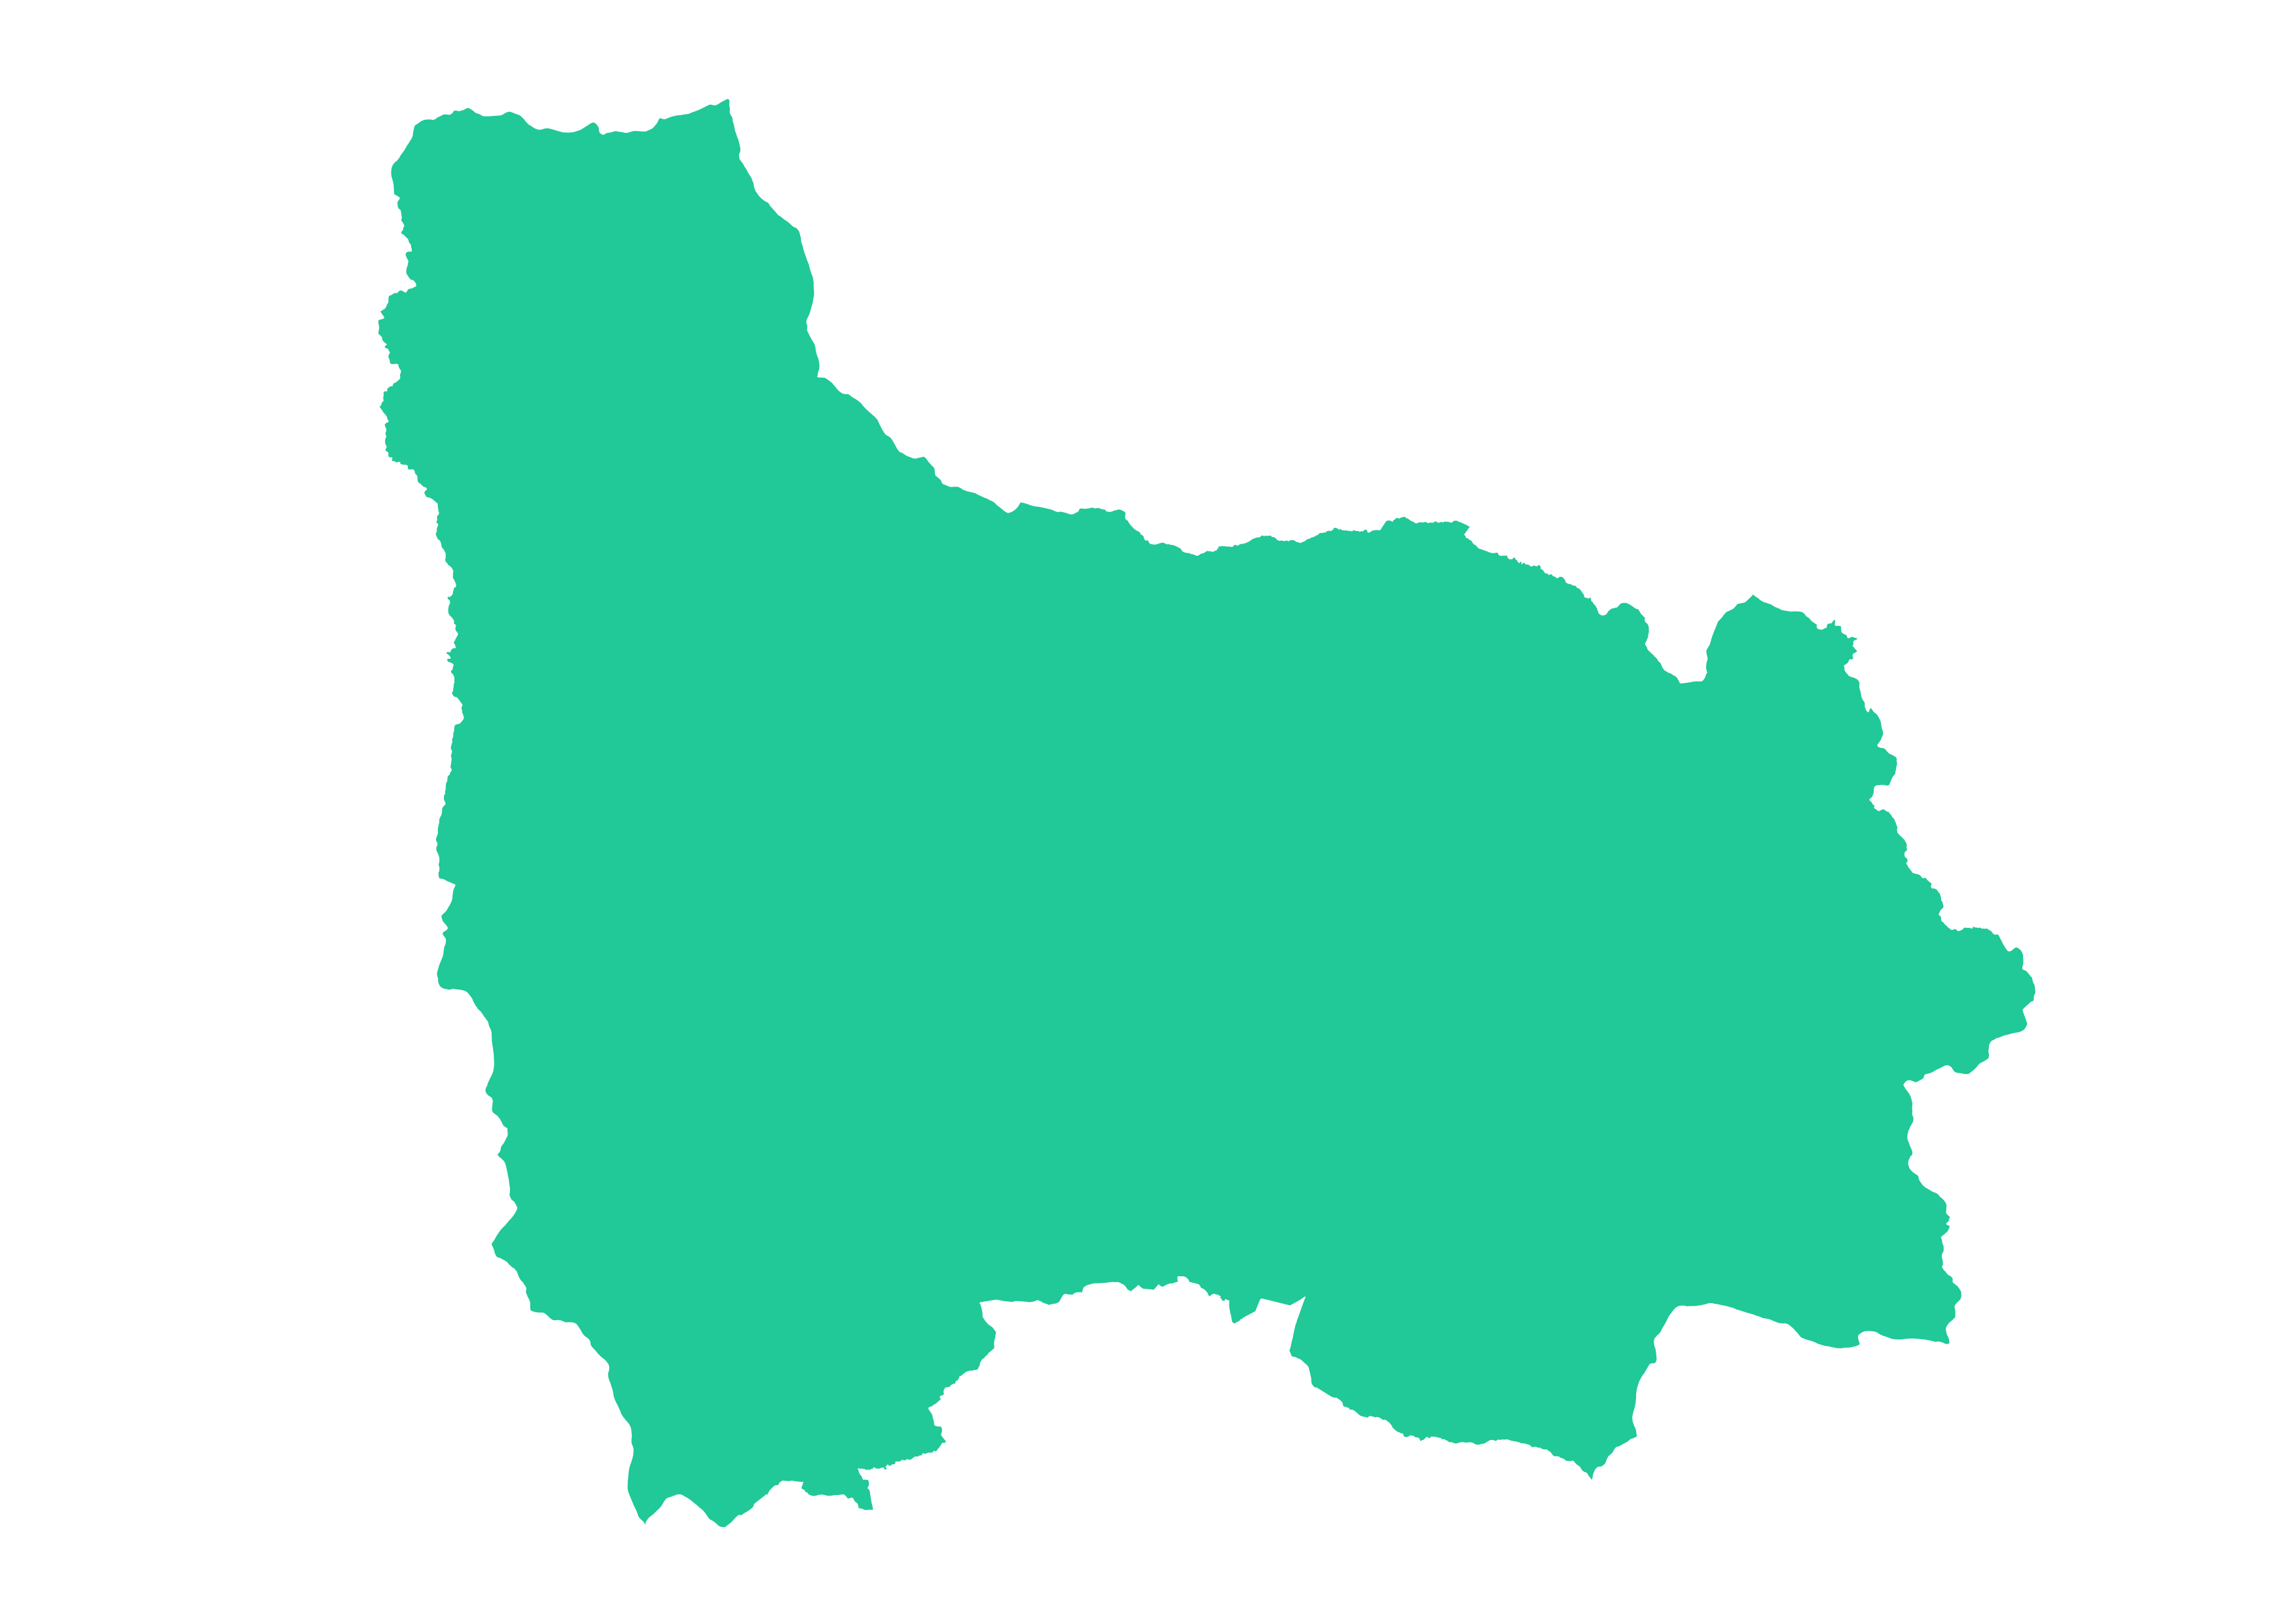

In [5]:
display(Image(filename=IMAGENES / "Medellin.png", width=500))

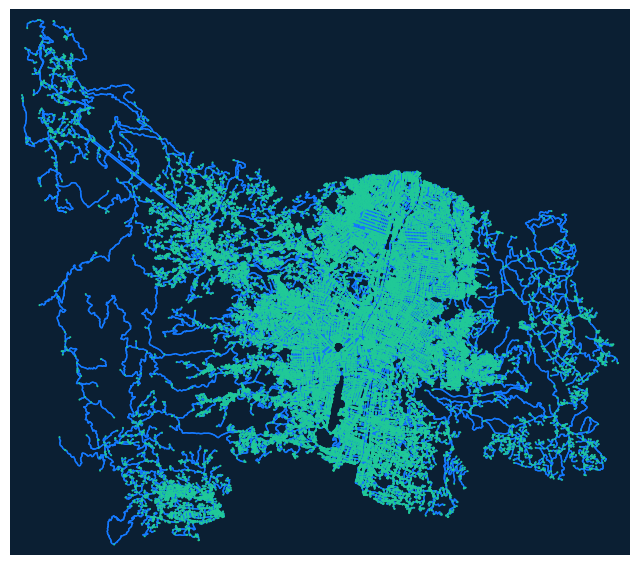

In [6]:
if EJECUTAR_EJEMPLOS:
    zona = gpd.read_file(GPKG / "Descargas" / "Medellin.gpkg")
    B = ox.graph.graph_from_polygon(zona.geometry.iloc[0], network_type="walk")
    fig, ax = ox.plot.plot_graph(B, **estilo)
else:
    display(Image(filename=IMAGENES / "Medellin_graph_from_polygon.png", width=500))

**2.3 Por punto y radio (`graph_from_point`):** se define una coordenada central y un radio en metros. Con 18 km alrededor de la Plaza Botero se cubre prácticamente todo el Valle de Aburrá; esta es la red que se guardó en `GPKG/Descargas/Walk_*_AMVA.gpkg`.

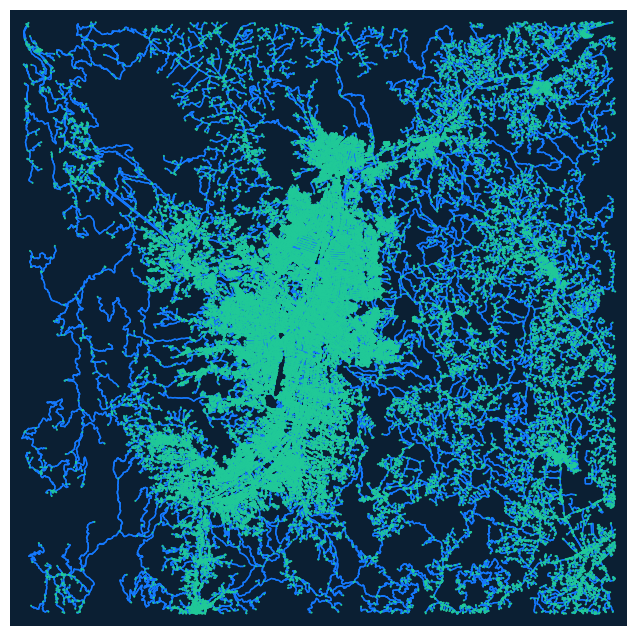

In [7]:
if EJECUTAR_EJEMPLOS:
    centroide = ox.geocoder.geocode("Plaza Botero, Medellín, Antioquia, Colombia")  # (lat, lon)
    C = ox.graph.graph_from_point(centroide, dist=18000, network_type="walk")
    fig, ax = ox.plot.plot_graph(C, **estilo)

    nodes, edges = ox.convert.graph_to_gdfs(C)
    nodes.to_file(GPKG / "Descargas" / "Walk_nodes_AMVA.gpkg", layer="nodos", driver="GPKG")
    edges.to_file(GPKG / "Descargas" / "Walk_edges_AMVA.gpkg", layer="ejes", driver="GPKG")
else:
    display(Image(filename=IMAGENES / "AMVA_graph_from_point.png", width=500))

<a id="paso-3"></a>
## 3. Red peatonal de La Aurora: descarga, recorte y limpieza

### 3.1 Territorio de análisis

El territorio es el límite político-administrativo de La Aurora con un *buffer* de 20 m, para capturar la red circundante que impacta directamente el sector (incluye la zona de la estación del Metrocable). Se dibujó en QGIS.

> **Sistema de coordenadas.** Las capas vienen en EPSG:4326 (grados). Para medir en metros todo se proyecta a **EPSG:9377 (MAGNA-SIRGAS Origen Nacional)**, el mismo de la capa de construcciones del catastro.

In [8]:
territorio = gpd.read_file(ENTRADAS / "Territorio_de_analisis_Aurora.gpkg")
area_km2 = territorio.to_crs(rp.CRS_METRICO).area.sum() / 1e6
print(f"CRS original: {territorio.crs.to_epsg()} | Área del territorio: {area_km2:.2f} km²")

CRS original: 4326 | Área del territorio: 1.56 km²


### 3.2 Obtención de la red peatonal

Se descarga la red `walk` dentro de un polígono **300 m más grande** que el territorio. El margen evita que se pierdan calles que cruzan el borde antes del recorte.

- `DESCARGAR = True` → descarga directa desde OpenStreetMap (necesita internet; los datos pueden cambiar con las ediciones de OSM).
- `DESCARGAR = False` → reutiliza la red del AMVA ya guardada en `GPKG/Descargas/`, lo que garantiza que todos trabajemos con **la misma versión** de la red.

In [9]:
DESCARGAR = False

poligono_descarga = rp.poligono_de_descarga(territorio, buffer_m=300)

if DESCARGAR:
    G_cruda = rp.descargar_red(poligono_descarga, network_type="walk")
else:
    G_cruda = rp.cargar_red_desde_gpkg(GPKG / "Descargas" / "Walk_nodes_AMVA.gpkg",
                                       GPKG / "Descargas" / "Walk_edges_AMVA.gpkg",
                                       poligono=poligono_descarga)

print(f"Red cruda: {len(G_cruda)} nodos | {G_cruda.number_of_edges()} aristas dirigidas")

Red cruda: 936 nodos | 2274 aristas dirigidas


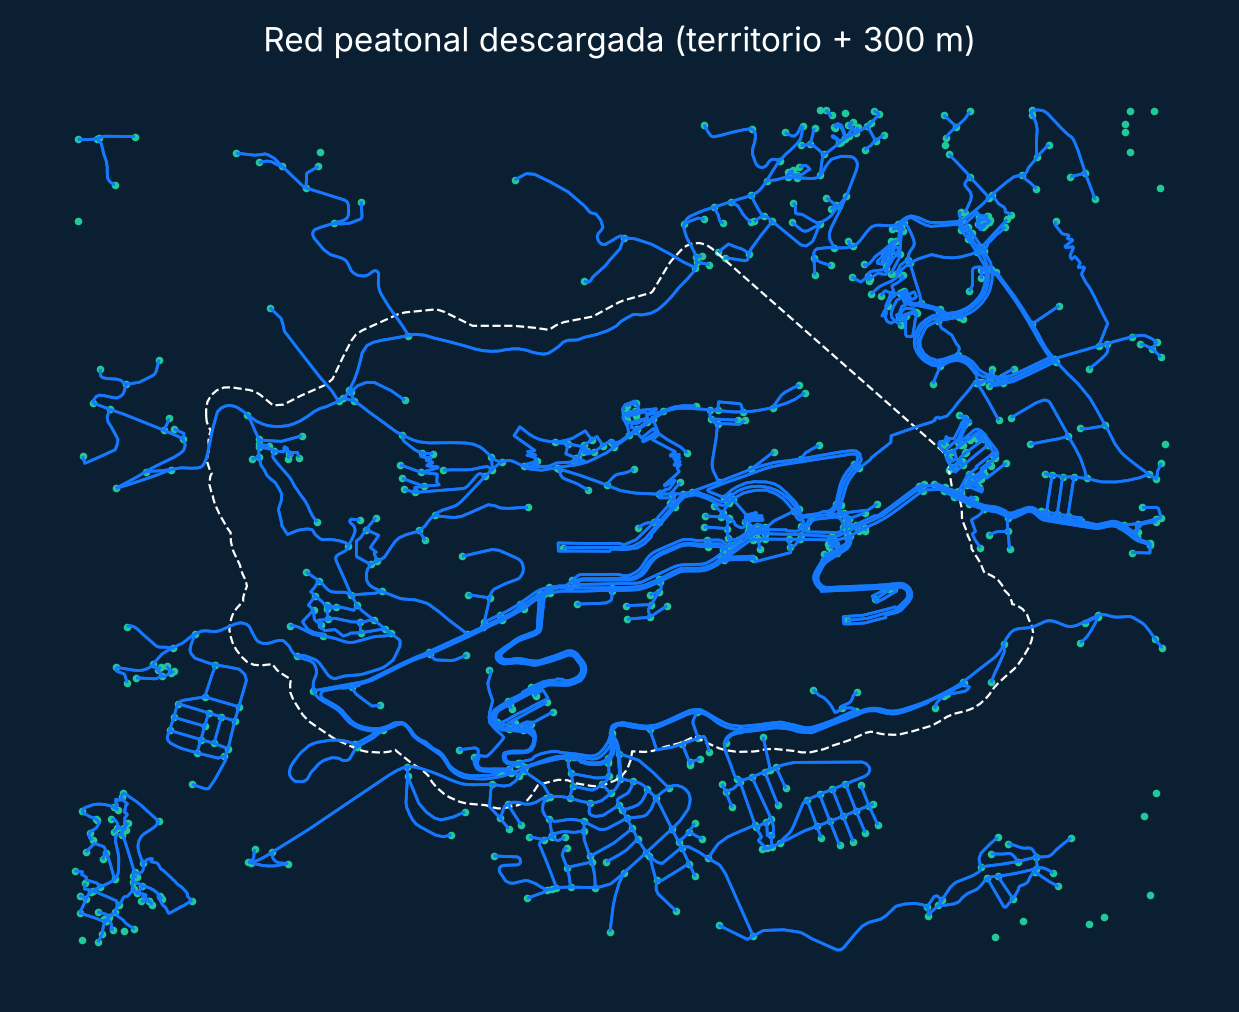

In [10]:
def dibujar(G, titulo, resaltar=None, color_resaltar="#FF4D4D", ax=None):
    """Red sobre el territorio de análisis; `resaltar` = GeoDataFrame de ejes a destacar."""
    nodos, ejes = ox.convert.graph_to_gdfs(G)
    crs = ejes.crs
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 6), facecolor=FONDO)
    ax.set_facecolor(FONDO)
    territorio.to_crs(crs).boundary.plot(ax=ax, color="white", lw=0.8, ls="--")
    ejes.plot(ax=ax, color=EJES, lw=1)
    nodos.plot(ax=ax, color=NODOS, markersize=3)
    if resaltar is not None and len(resaltar):
        resaltar.to_crs(crs).plot(ax=ax, color=color_resaltar, lw=2)
    ax.set_title(titulo, color="white")
    ax.set_axis_off()
    return ax

dibujar(G_cruda, "Red peatonal descargada (territorio + 300 m)");

### 3.3 Recorte por el polígono del territorio

`ox.truncate.truncate_graph_polygon` conserva los **nodos que caen dentro del polígono** y las aristas entre ellos. Con `truncate_by_edge=False` una arista se conserva sólo si sus dos extremos están adentro.

In [11]:
G_recorte = rp.recortar_red(G_cruda, territorio, truncate_by_edge=False)
print(f"Tras el recorte: {len(G_recorte)} nodos | {G_recorte.number_of_edges()} aristas dirigidas")
rp.resumen_componentes(G_recorte)

Tras el recorte: 353 nodos | 926 aristas dirigidas


,componente,nodos,ejes,longitud_m
0,0,350,926,66498.444934
1,1,1,0,0.000000
2,2,1,0,0.000000
3,3,1,0,0.000000


El recorte puede dejar **componentes desconectados**: pedazos de calle que quedaron sueltos al cortar por el borde. Se conserva sólo el componente principal (débilmente conexo, porque en la red peatonal se puede caminar en ambos sentidos).

In [12]:
G_recorte = rp.conservar_componente_principal(G_recorte)
print(f"Componente principal: {len(G_recorte)} nodos | {G_recorte.number_of_edges()} aristas dirigidas")

Componente principal: 350 nodos | 926 aristas dirigidas


### 3.4 Exclusiones manuales (criterio del equipo)

El equipo revisó la red y retiró algunos ejes: sobre todo vías del perímetro del polígono (tramos de la Antigua Vía al Mar, Calle 63, Calle 62D y Calle 64, y sus conexiones) que no hacen parte del tejido del barrio. Para ubicar un eje y conocer su `u`, `v` y `key`, se puede abrir en QGIS la capa `Resultados/Ejes_excluidos.gpkg` que exporta la celda de abajo.

Para que ese criterio **sea reproducible**, los ejes retirados quedaron listados en `GPKG/Aurora/Entradas/Exclusiones_manuales_Aurora.csv` (identificados por `u`, `v`, `key` de OSM). Para cambiar el criterio basta con editar ese archivo: agregar o borrar filas, sin tocar código. Se elimina también el sentido contrario de cada eje, para que ninguna calle quede "a medias".

In [13]:
exclusiones = pd.read_csv(ENTRADAS / "Exclusiones_manuales_Aurora.csv")
print(f"{len(exclusiones)} aristas listadas para excluir")
exclusiones.head()


112 aristas listadas para excluir


,u,v,key,osmid,highway,name,length,motivo
0,7116043635,9387600843,1,"[761631024, 914661400, 914661401, 914661399]",service,NaN,387.2,Exclusión manual del equipo (vía perimetral o ...
1,9387600843,7116043635,1,"[914661400, 914661401, 761631024, 914661399]",service,NaN,387.2,Exclusión manual del equipo (vía perimetral o ...
2,3914298406,3266149601,0,320118234,tertiary,Antigua Vía al Mar,203.1,Exclusión manual del equipo (vía perimetral o ...
3,3266149601,3914298406,0,320118234,tertiary,Antigua Vía al Mar,203.1,Exclusión manual del equipo (vía perimetral o ...
4,3266149601,3266150413,0,"[320118234, 654116682]","['tertiary', 'secondary']",Antigua Vía al Mar,722.8,Exclusión manual del equipo (vía perimetral o ...


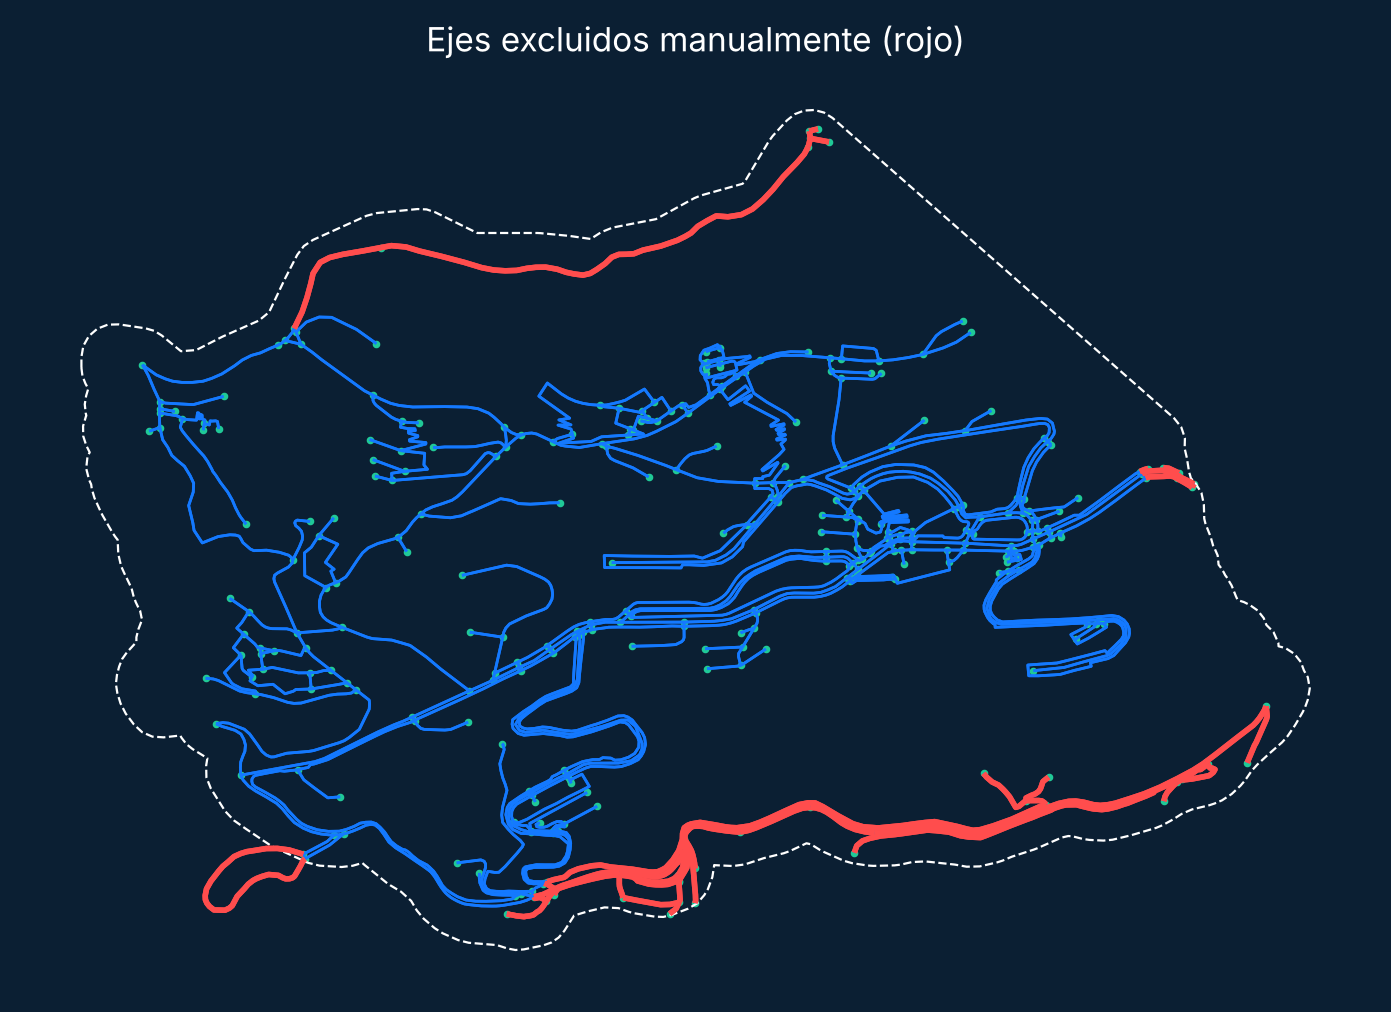

In [14]:
ejes_recorte = ox.convert.graph_to_gdfs(G_recorte, nodes=False)
idx = [(u, v, k) for u, v, k in zip(exclusiones.u, exclusiones.v, exclusiones.key) if (u, v, k) in ejes_recorte.index]
dibujar(G_recorte, "Ejes excluidos manualmente (rojo)", resaltar=ejes_recorte.loc[idx]);
excluidos = ejes_recorte.loc[idx].reset_index()
for c in excluidos.columns:
    if c != "geometry" and excluidos[c].map(lambda x: isinstance(x, list)).any():
        excluidos[c] = excluidos[c].astype(str)
excluidos.to_file(RESULTADOS / "Ejes_excluidos.gpkg", layer="excluidos", driver="GPKG")

### 3.5 Eliminación de nodos y ejes que no conectan con la red

Al quitar ejes pueden quedar nodos aislados o ramas sueltas. Se vuelven a contar los componentes y se conserva otra vez sólo el principal: así **todo nodo de la red final se puede alcanzar desde cualquier otro**, condición necesaria para calcular distancias y centralidades.

In [15]:
G_excl = rp.aplicar_exclusiones(G_recorte, exclusiones, ambos_sentidos=True)
display(rp.resumen_componentes(G_excl))

G_red = rp.conservar_componente_principal(G_excl)
print(f"Red limpia: {len(G_red)} nodos | {G_red.number_of_edges()} aristas dirigidas")

,componente,nodos,ejes,longitud_m
0,0,304,814,55587.930775


Red limpia: 304 nodos | 814 aristas dirigidas


### 3.6 Proyección, actualización de atributos y verificación

1. Se proyecta el grafo a EPSG:9377 (metros).
2. Se recalcula `street_count`: OSMnx lo calculó sobre la red completa del AMVA, así que los nodos del borde conservaban el valor viejo. Es clave para índices como la proporción de callejones sin salida (*R_dead*).
3. Se verifica la red: un solo componente, sin nodos aislados, cada calle en ambos sentidos y geometrías bien orientadas.

La red que produce este notebook es la **red oficial del proyecto**: cualquier cambio se hace editando el CSV de exclusiones y volviendo a ejecutar, no editando la red a mano en QGIS.

In [16]:
G_red = rp.recalcular_street_count(G_red)
G_red = ox.projection.project_graph(G_red, to_crs=rp.CRS_METRICO)
pd.Series(rp.verificar_red(G_red), name="Red limpia").to_frame()

,Red limpia
nodos,304.00
ejes_dirigidos,814.00
componentes,1.00
nodos_aislados,0.00
ejes_sin_sentido_contrario,0.00
geometrias_mal_orientadas,0.00
longitud_red_km (sin duplicar sentidos),27.79


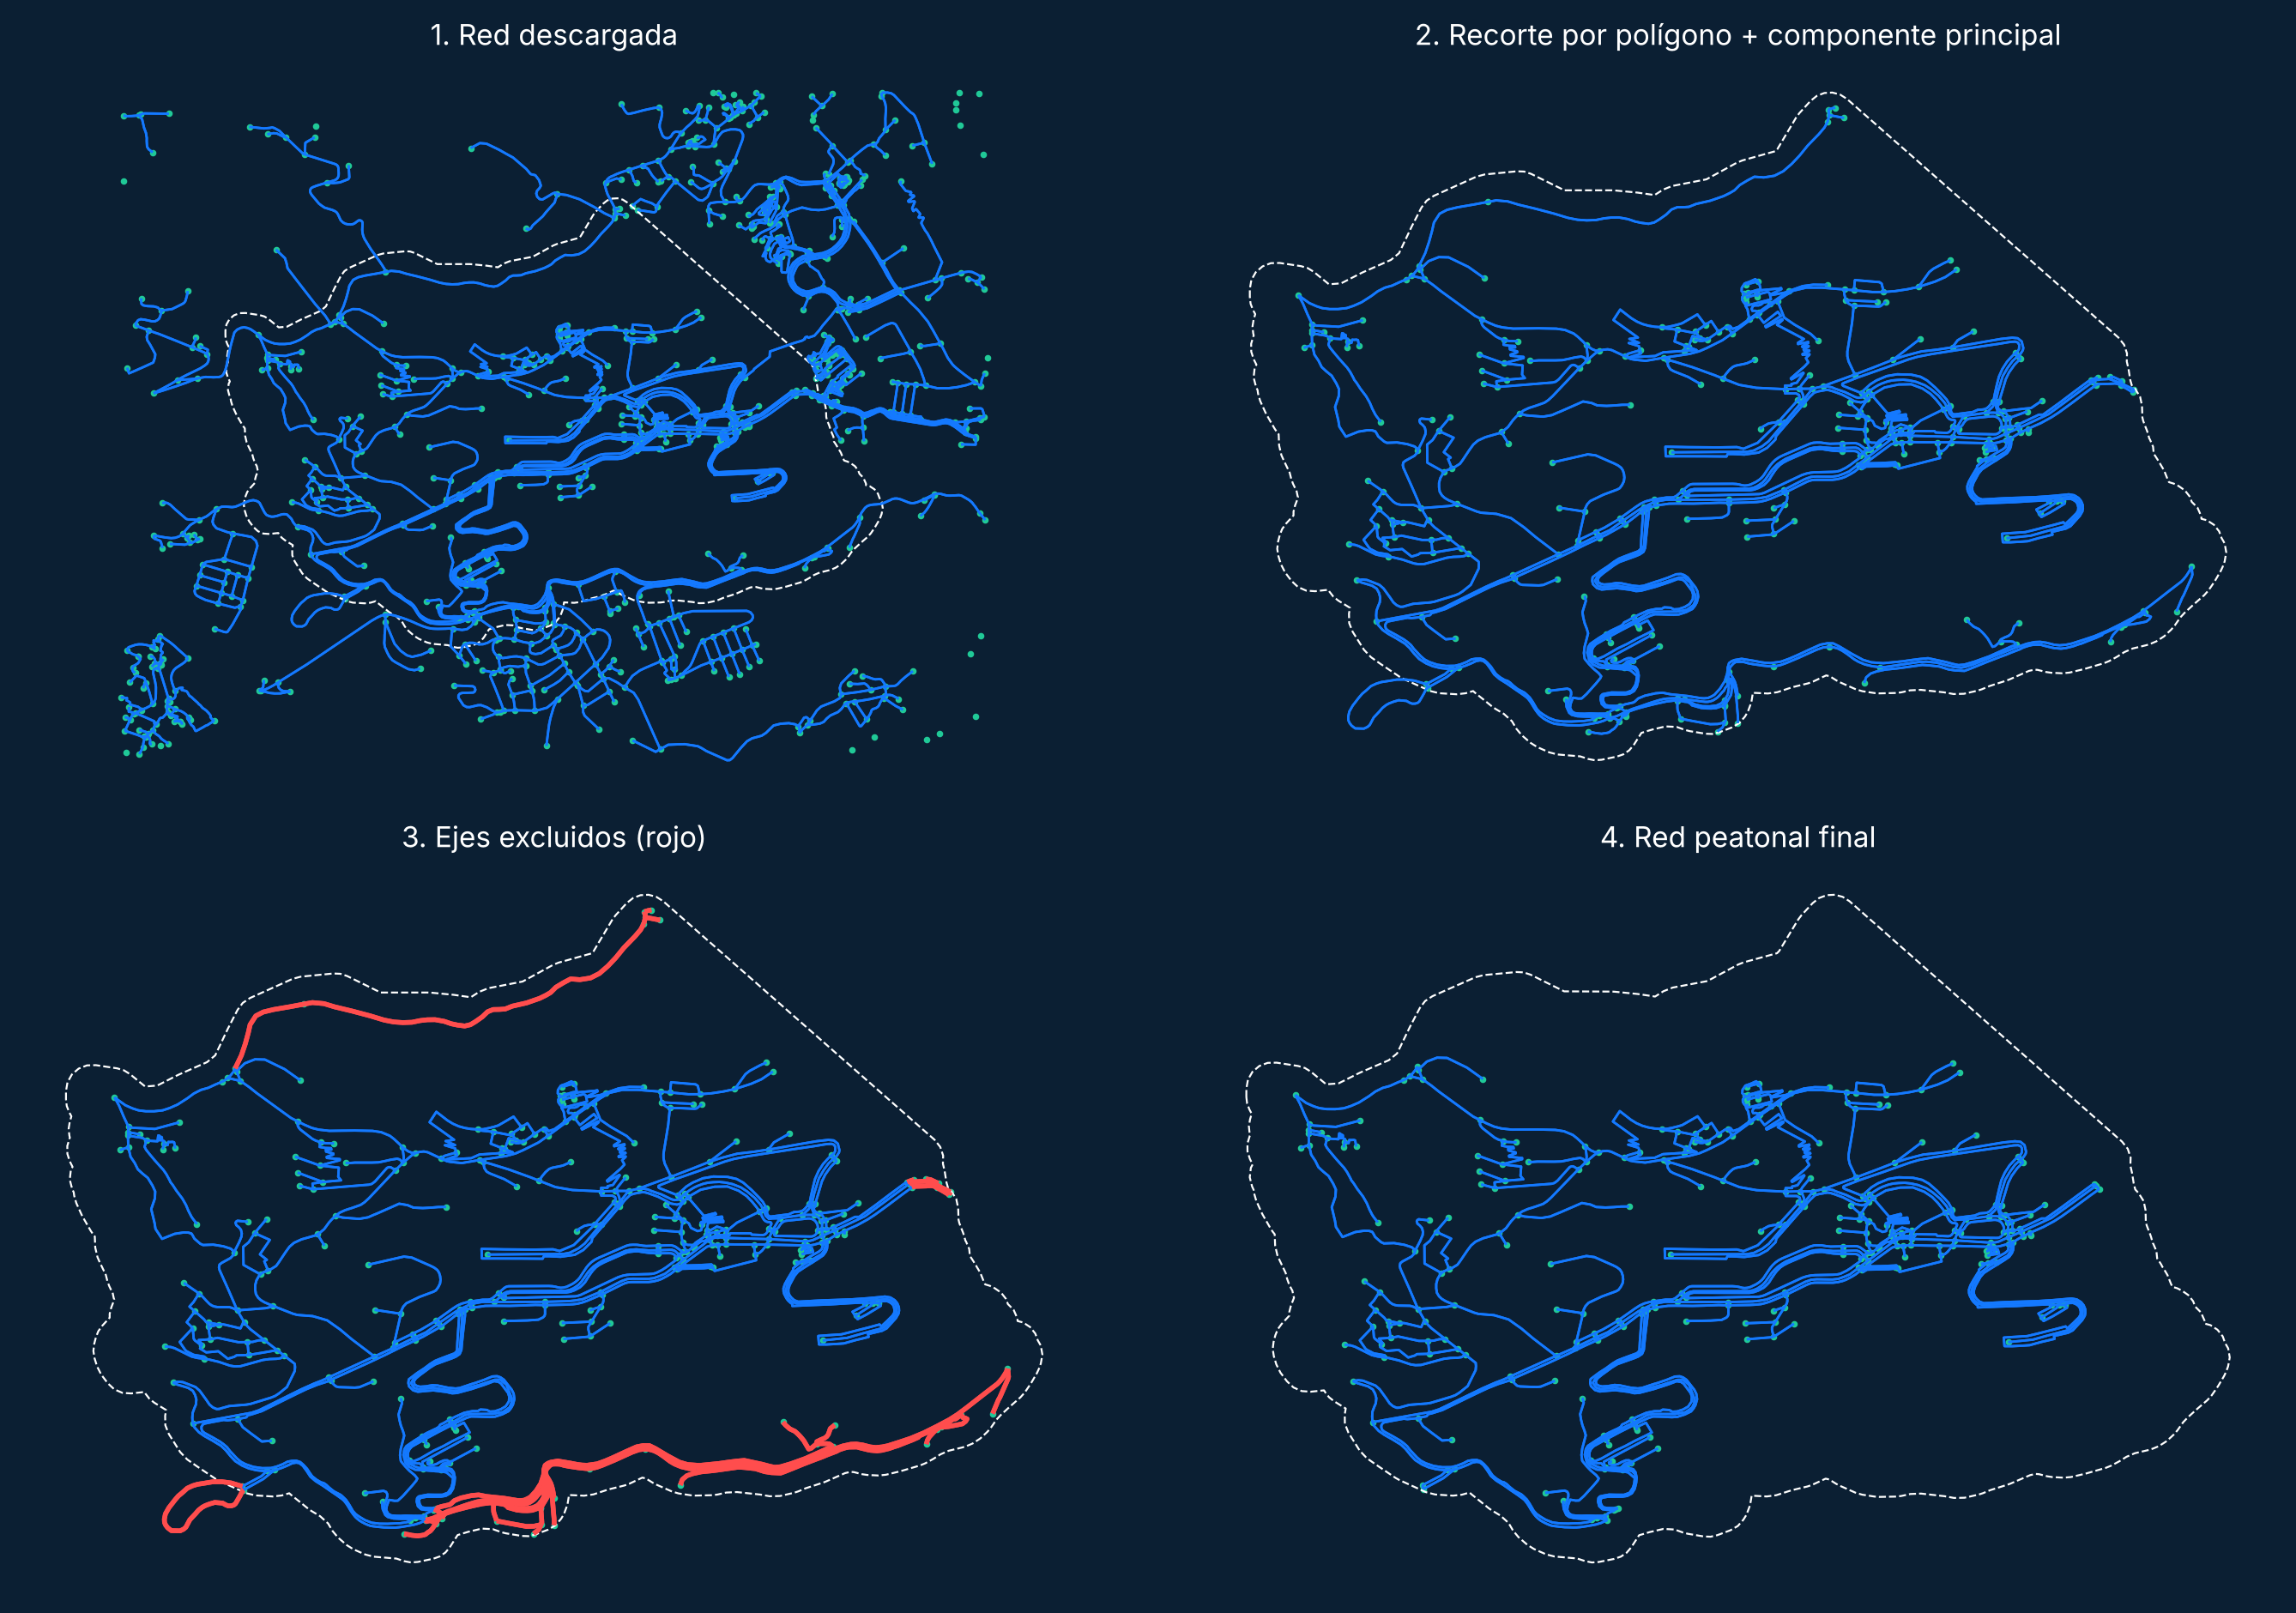

In [17]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9.5), facecolor=FONDO)
dibujar(G_cruda,   "1. Red descargada", ax=axs[0, 0])
dibujar(G_recorte, "2. Recorte por polígono + componente principal", ax=axs[0, 1])
dibujar(G_recorte, "3. Ejes excluidos (rojo)", resaltar=ejes_recorte.loc[idx], ax=axs[1, 0])
dibujar(G_red,     "4. Red peatonal final", ax=axs[1, 1])
plt.tight_layout()
fig.savefig(IMAGENES / "Aurora_flujo_red.png", dpi=130, facecolor=FONDO, bbox_inches="tight")

<a id="paso-4"></a>
## 4. Integración de los puntos de interés a la red

Para medir distancias **por la red** desde cualquier nodo hasta un servicio, el servicio tiene que ser un nodo del grafo. Cada punto de interés (POI) se integra así:

```
        POI ●                         POI ●
            ┆ distancia de ajuste         ┆
   u ───────┼──────── v      ──►    u ────◆──── v      ◆ = nodo nuevo (id negativo)
         punto de acceso                  u→◆, ◆→v (y sus sentidos contrarios)
```

1. Se busca la **arista más cercana** al POI (`ox.distance.nearest_edges`, en metros).
2. Se **proyecta** el POI sobre esa arista: ese es su punto de acceso a la red.
3. Si el punto de acceso queda a menos de 1 m de un nodo existente, el POI se asocia a ese nodo.
4. Si no, la arista se **divide en dos** en el punto de acceso y se crea un nodo nuevo. La longitud se reparte proporcionalmente y se hace lo mismo con la arista del sentido contrario.

Los nodos creados llevan `tipo_nodo = "poi"`, y los existentes que reciben un POI llevan `"red+poi"`. Así se pueden filtrar después.

### 4.1 Puntos de interés y categorías

Para el SAWI cada destino debe tener un **tipo de servicio** *k*. La capa original no trae categoría, así que abajo hay una **propuesta inicial que el equipo debe revisar**.

In [18]:
pois = gpd.read_file(ENTRADAS / "Puntos_de_interes_Aurora.gpkg")
pois["LUGARES"] = pois["LUGARES"].str.strip()

# PROPUESTA de categorías (revisar con el equipo)
categorias = {
    "Unidad Hospitalaria Nuevo Occidente Metrosalud": "Salud",
    "Estación del metrocable La Aurora": "Transporte",
    "IE Lusitania Paz De Colombia": "Educación",
    "I.E. Ciudadela Nuevo Occidente": "Educación",
    "UVA (Unidades de Vida Articulada) Nuevo Occidente": "Cultura y recreación",
    "Ludoteca Casa San Martín": "Cultura y recreación",
    "Jardín Infantil Comienzo La Aurora": "Educación",
    "Sección Escuela El Tirol II": "Educación",
    "Liceo Santa Margarita": "Educación",
    "Centro De Protección Al Adulto Mayor EN BUENAS MANOS": "Bienestar social",
    "Droguería Villasuramericana": "Salud",
    "Tienda D1 La Aurora": "Abastecimiento",
    "Gimnasio Golden Fitness": "Deporte",
    "Papelería V&R": "Comercio y servicios",
    "Mirador de La Cascada": "Espacio público",
    "Restaurante La Ricuras De La Cascada": "Comercio y servicios",
    "Ferretería Nuevo Occidente": "Comercio y servicios",
    "Minimercado j.j. Matías": "Abastecimiento",
    "Mercado Las Veletas": "Abastecimiento",
    "Tienda El Amigo": "Abastecimiento",
    "Panadería La Cinta": "Abastecimiento",
    "Restaurante El Palacio de las Fresas": "Comercio y servicios",
    "Pizzería Rangel San Cristobal": "Comercio y servicios",
}
pois["categoria"] = pois["LUGARES"].map(categorias)
assert pois["categoria"].notna().all(), "Hay POIs sin categoría"
pois[["LUGARES", "categoria"]].value_counts("categoria").to_frame("n")

,n
categoria,
Educación,5
Abastecimiento,5
Comercio y servicios,5
Salud,2
Cultura y recreación,2
Transporte,1
Bienestar social,1
Deporte,1
Espacio público,1


### 4.2 Integración

In [19]:
G_poi, pois_red = rp.integrar_pois(G_red, pois, col_nombre="LUGARES",
                                   tolerancia_nodo_m=1.0, columnas_extra=["categoria"])

pois_red[["LUGARES", "categoria", "nodo_red", "metodo", "dist_ajuste_m"]] \
    .sort_values("dist_ajuste_m", ascending=False).reset_index(drop=True)

,LUGARES,categoria,nodo_red,metodo,dist_ajuste_m
0,Centro De Protección Al Adulto Mayor EN BUENAS...,Bienestar social,3914296307,nodo existente,59.12
1,UVA (Unidades de Vida Articulada) Nuevo Occidente,Cultura y recreación,-4,arista dividida,56.56
2,Liceo Santa Margarita,Educación,-7,arista dividida,52.51
3,I.E. Ciudadela Nuevo Occidente,Educación,9387687691,nodo existente,34.41
4,Gimnasio Golden Fitness,Deporte,-10,arista dividida,29.78
5,IE Lusitania Paz De Colombia,Educación,-3,arista dividida,25.84
6,Ludoteca Casa San Martín,Cultura y recreación,-5,arista dividida,24.65
7,Sección Escuela El Tirol II,Educación,9387600868,nodo existente,22.47
8,Unidad Hospitalaria Nuevo Occidente Metrosalud,Salud,-1,arista dividida,16.83
9,Mirador de La Cascada,Espacio público,-12,arista dividida,16.18


**Control de calidad.** Una distancia de ajuste grande (> 50 m) indica que el POI quedó lejos de la red: puede faltar un sendero en OSM, puede estar mal ubicado el punto o puede ser correcto (un equipamiento grande con acceso por otra calle). Hay que revisar esos casos en QGIS con la capa `lineas_ajuste` que se exporta abajo.

In [20]:
revisar = pois_red[pois_red["dist_ajuste_m"] > 50][["LUGARES", "dist_ajuste_m"]]
print(f"POIs a revisar (> 50 m de la red): {len(revisar)}")
display(revisar)

dup = pois_red[pois_red.geometry.duplicated(keep=False)][["LUGARES"]]
if len(dup):
    print("⚠️ POIs con coordenadas idénticas (posible error de digitación):")
    display(dup)

POIs a revisar (> 50 m de la red): 3


,LUGARES,dist_ajuste_m
4,UVA (Unidades de Vida Articulada) Nuevo Occidente,56.56
8,Liceo Santa Margarita,52.51
9,Centro De Protección Al Adulto Mayor EN BUENAS...,59.12


⚠️ POIs con coordenadas idénticas (posible error de digitación):


,LUGARES
21,Restaurante El Palacio de las Fresas
22,Pizzería Rangel San Cristobal


In [21]:
pd.Series(rp.verificar_red(G_poi), name="Red con POIs").to_frame()

,Red con POIs
nodos,322.00
ejes_dirigidos,850.00
componentes,1.00
nodos_aislados,0.00
ejes_sin_sentido_contrario,0.00
geometrias_mal_orientadas,0.00
longitud_red_km (sin duplicar sentidos),27.79


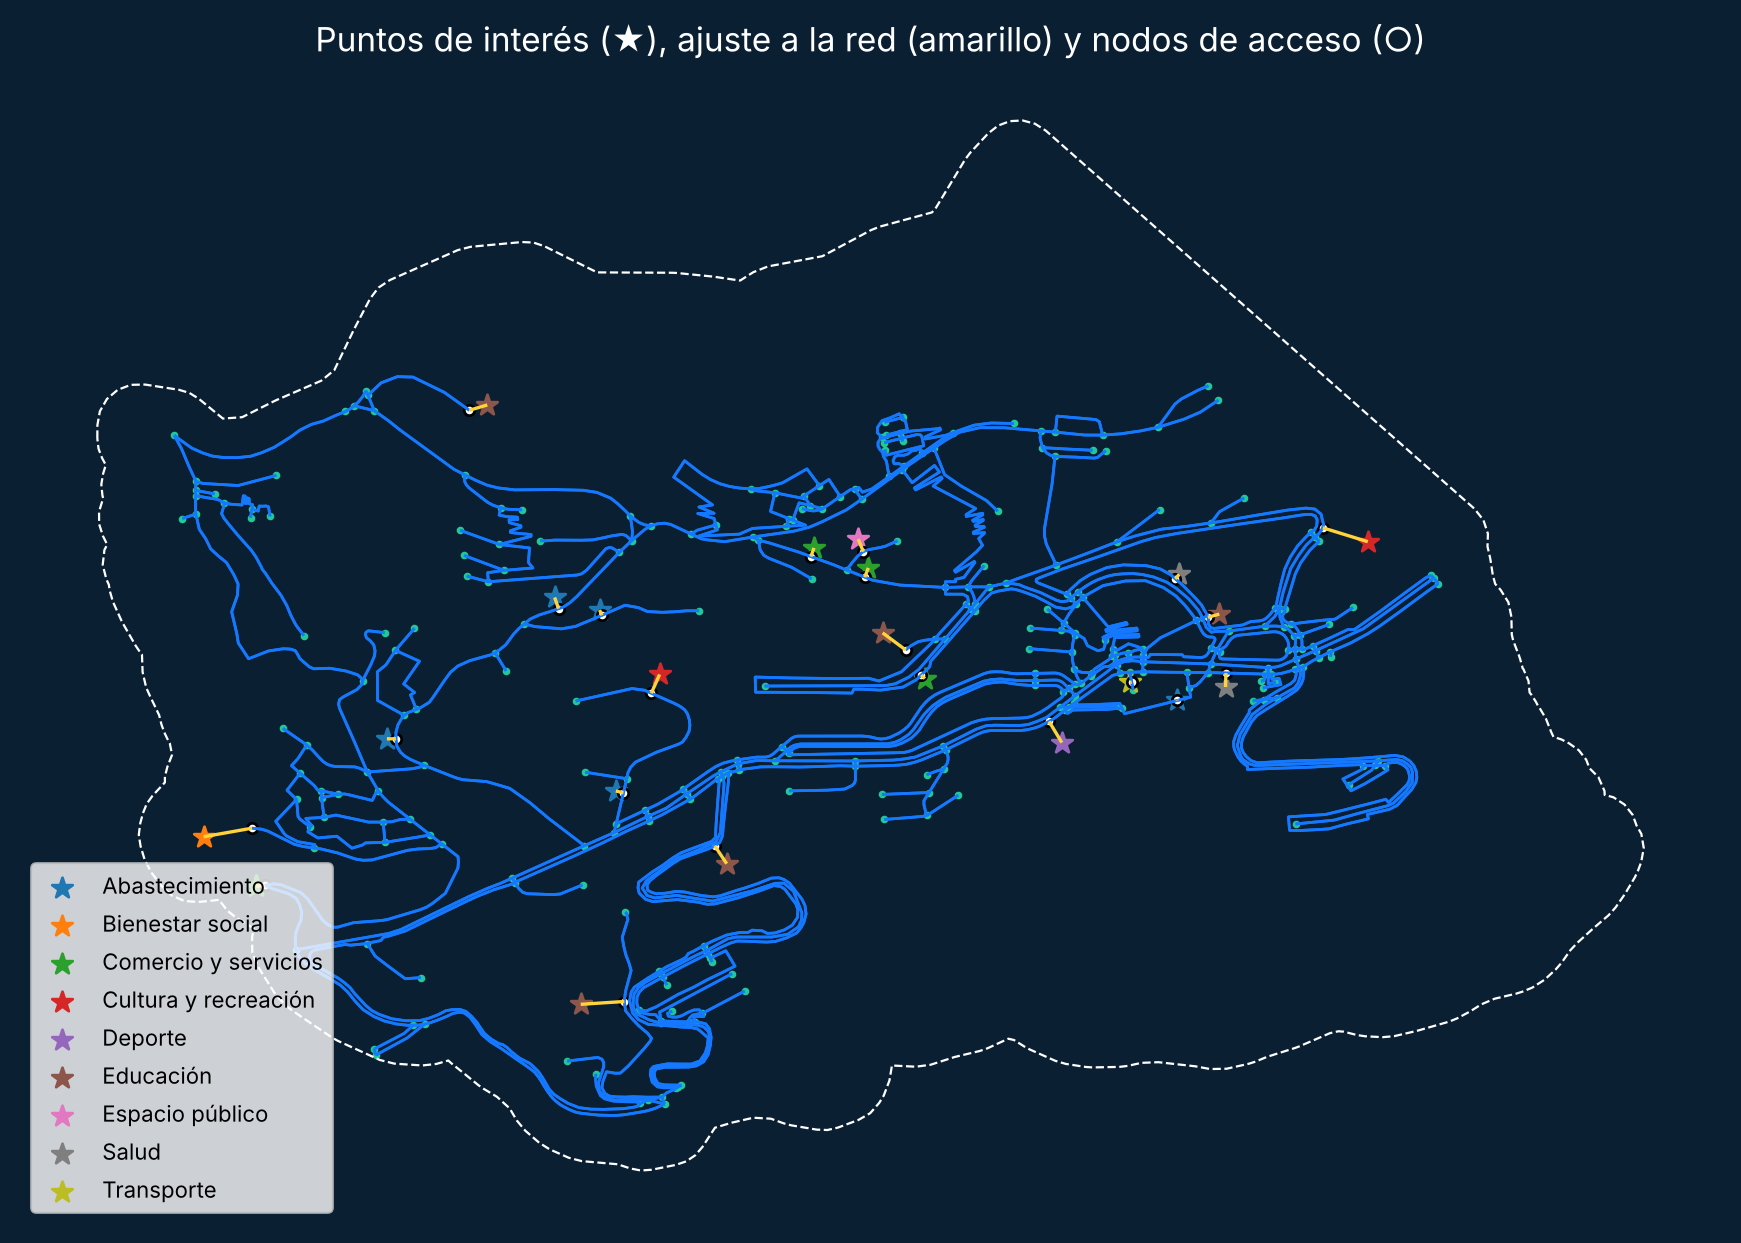

In [22]:
nodos_poi, ejes_poi = ox.convert.graph_to_gdfs(G_poi)
lineas = rp.lineas_de_ajuste(pois_red)

fig, ax = plt.subplots(figsize=(11, 7.5), facecolor=FONDO)
ax.set_facecolor(FONDO)
territorio.to_crs(rp.CRS_METRICO).boundary.plot(ax=ax, color="white", lw=0.8, ls="--")
ejes_poi.plot(ax=ax, color=EJES, lw=1)
nodos_poi[nodos_poi.tipo_nodo == "red"].plot(ax=ax, color=NODOS, markersize=3)
lineas.plot(ax=ax, color="#FFD43B", lw=1.2)
pois_red.plot(ax=ax, column="categoria", markersize=60, marker="*", legend=True,
              cmap="tab10", legend_kwds={"loc": "lower left", "fontsize": 8})
nodos_poi[nodos_poi.tipo_nodo != "red"].plot(ax=ax, color="white", markersize=14, edgecolor="k")
ax.set_title("Puntos de interés (★), ajuste a la red (amarillo) y nodos de acceso (○)", color="white")
ax.set_axis_off()
fig.savefig(IMAGENES / "Aurora_pois_integrados.png", dpi=130, facecolor=FONDO, bbox_inches="tight")

<a id="paso-5"></a>
## 5. Exportación de resultados

| Archivo | Contenido | Para qué |
|---|---|---|
| `Red_Aurora.gpkg` | capas `nodos`, `ejes` | Red limpia **sin** POIs → índices de morfología y centralidad |
| `Red_Aurora_POIs.gpkg` | capas `nodos`, `ejes`, `pois`, `lineas_ajuste` | Red **con** POIs → accesibilidad (A<sub>ik</sub>, SAWI) y revisión en QGIS |
| `*.graphml` | el grafo completo | Volver a cargar la red en Python sin repetir este notebook |

Todo queda en EPSG:9377.

> ⚠️ **¿Por qué dos redes?** Los nodos de POI tienen grado 2 (sólo parten una calle). Si se incluyen en el cálculo de densidad de intersecciones, *street_count* o centralidades, **distorsionan los resultados**. Para morfología se usa la red sin POIs.

In [23]:
rp.exportar_red(G_red, RESULTADOS / "Red_Aurora.gpkg", RESULTADOS / "Red_Aurora.graphml")

pois_export = pois_red.drop(columns=["Longitud (X)", "Latitud (Y)"])
rp.exportar_red(G_poi, RESULTADOS / "Red_Aurora_POIs.gpkg", RESULTADOS / "Red_Aurora_POIs.graphml",
                capas_extra={"pois": pois_export, "lineas_ajuste": lineas.drop(columns=["Longitud (X)", "Latitud (Y)"])})

for f in sorted(RESULTADOS.iterdir()):
    print(f"{f.name:<28} {f.stat().st_size/1024:8.0f} KB")

Ejes_excluidos.gpkg               140 KB
Red_Aurora.gpkg                   380 KB
Red_Aurora.graphml                444 KB
Red_Aurora_POIs.gpkg              448 KB
Red_Aurora_POIs.graphml           471 KB


Para volver a cargar la red en otro notebook:

```python
import osmnx as ox
G = ox.io.load_graphml("../GPKG/Aurora/Resultados/Red_Aurora_POIs.graphml")
```

<a id="paso-6"></a>
## 6. Primer vistazo topológico

Una comprobación rápida de que la red sirve para los cálculos: estadísticas básicas de OSMnx (sobre la red **sin** POIs; las densidades están por km²) y la distancia por la red desde cada nodo hasta el servicio más cercano de cada categoría (sobre la red **con** POIs).

In [24]:
stats = ox.stats.basic_stats(G_red, area=area_km2 * 1e6)
claves = ["n", "m", "k_avg", "edge_length_total", "street_length_total", "street_segment_count",
          "intersection_count", "streets_per_node_avg", "circuity_avg", "intersection_density_km", "street_density_km"]
tabla = pd.Series({k: stats[k] for k in claves})
tabla["R_dead (proporción de callejones sin salida)"] = stats["streets_per_node_proportions"].get(1, 0)
tabla.round(3).to_frame("valor")

,valor
n,304.000
m,814.000
k_avg,5.355
edge_length_total,55587.931
street_length_total,27793.965
street_segment_count,407.000
intersection_count,235.000
streets_per_node_avg,2.678
circuity_avg,1.276
intersection_density_km,150.852


In [25]:
G_poi_und = ox.convert.to_undirected(G_poi)

distancias = {}
for cat, grupo in pois_red.groupby("categoria"):
    fuentes = set(grupo["nodo_red"])
    distancias[cat] = nx.multi_source_dijkstra_path_length(G_poi_und, fuentes, weight="length")
dist = pd.DataFrame(distancias).loc[[n for n in G_red.nodes]]  # sólo nodos de la red original

dist.describe().T[["mean", "50%", "max"]].round(0).rename(
    columns={"mean": "media (m)", "50%": "mediana (m)", "max": "máxima (m)"})

,media (m),mediana (m),máxima (m)
Abastecimiento,387.0,304.0,1303.0
Bienestar social,1187.0,1281.0,2077.0
Comercio y servicios,523.0,502.0,1145.0
Cultura y recreación,619.0,563.0,1492.0
Deporte,653.0,604.0,1668.0
Educación,369.0,350.0,931.0
Espacio público,747.0,644.0,2177.0
Salud,672.0,622.0,1899.0
Transporte,671.0,600.0,1796.0


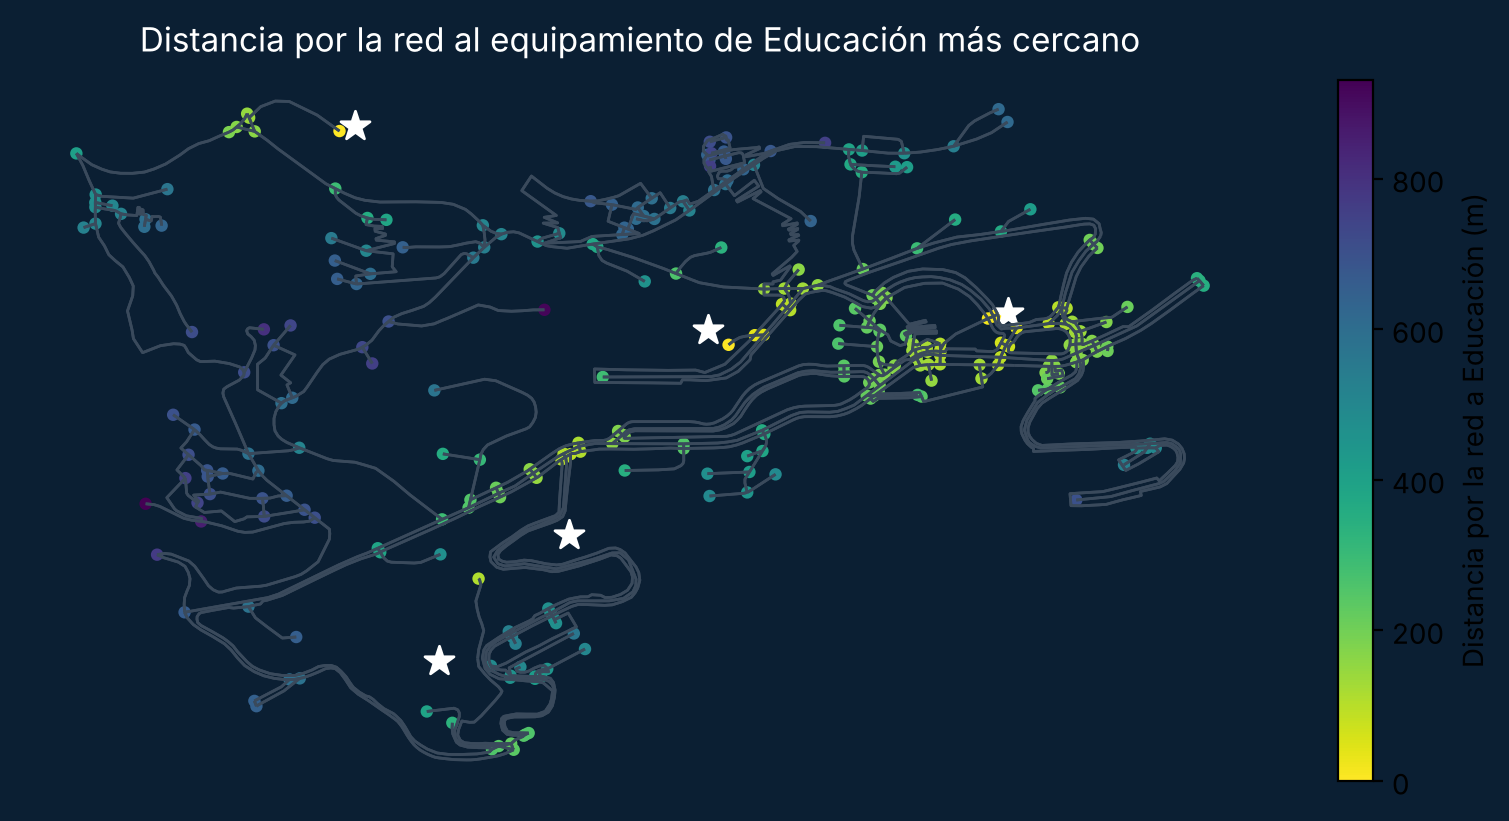

In [26]:
nodos_dist = nodos_poi.loc[dist.index].join(dist)
cat = "Educación"

fig, ax = plt.subplots(figsize=(10, 6.5), facecolor=FONDO)
ax.set_facecolor(FONDO)
ejes_poi.plot(ax=ax, color="#3a4a5c", lw=1)
nodos_dist.plot(ax=ax, column=cat, cmap="viridis_r", markersize=12, legend=True,
                legend_kwds={"label": f"Distancia por la red a {cat} (m)", "shrink": 0.7})
pois_red[pois_red.categoria == cat].plot(ax=ax, color="white", marker="*", markersize=120)
ax.set_title(f"Distancia por la red al equipamiento de {cat} más cercano", color="white")
ax.set_axis_off();

> Estas distancias son **planas**: aún no consideran la pendiente. Para el tiempo de caminata con Naismith-Langmuir (ec. 12 del compendio) hay que asignar elevación a los nodos con un DEM y calcular la pendiente de cada arista.

<a id="paso-7"></a>
## 7. Próximos pasos

- [ ] Validar con el equipo las categorías de los POIs y revisar los que quedaron a más de 50 m de la red.
- [ ] Corregir en la capa original los POIs con coordenadas duplicadas.
- [ ] Asignar elevación a los nodos (DEM) y calcular la pendiente de cada arista.
- [ ] Notebook de **índices de conectividad** (compendio, bloques 1 y 2): CC, CB, CS, CI, κ̄, circuidad, R_dead, H<sub>θ</sub>.
- [ ] Notebook de **accesibilidad** (bloque 3): A<sub>ik</sub> con umbral de 15 min y SAWI.